# Lab Sheet 09 — Data Analytics and Visualization
**MCA201P | Semester III | Session 2026–27**

## Objectives
1. Clean and explore COVID-like country data and business sales records.
2. Visualize cases, recoveries, deaths, vaccinations and country comparisons.
3. Generate interactive sales charts, RFM customer segmentation and concise EDA findings.

> **Data provenance:** Both datasets are explicitly **SYNTHETIC** teaching examples. Charts are *not* real public-health or company performance figures.

**Requirements:** Run from the same folder as `lab_09.py` (see `README.md` for setup).

## Step 1 — Generate reproducible sample data (seeded)

In [1]:
from generate_labs_09_10_data import make_covid, make_sales
covid_df = make_covid()
sales_df = make_sales()
print("COVID records:", covid_df.shape, "Sales records:", sales_df.shape)
display(covid_df.head(3)); display(sales_df.head(3))

COVID records: (450, 7) Sales records: (2000, 8)


,date,country,population,confirmed,recovered,deaths,people_vaccinated
0,2021-01-01,Country A (simulated),1200000,1164,935,13,6970
1,2021-01-02,Country A (simulated),1200000,2403,1923,33,14847
2,2021-01-03,Country A (simulated),1200000,3673,2943,55,21460


,order_id,date,customer_id,region,product,quantity,sales,cost
0,S00000,2025-08-19,C070,North,Keyboard,4,6868.90,4170.87
1,S00001,2025-01-03,C142,South,Webcam,4,12499.70,8978.44
2,S00002,2025-02-24,C060,South,Keyboard,1,1611.21,1262.67


## Step 2 — Check data quality and summary statistics

In [2]:
for name, frame in [("COVID", covid_df), ("Sales", sales_df)]:
    print(name, "missing values:\n", frame.isna().sum())
    display(frame.describe(include="all"))

COVID missing values:
 date                 0
country              0
population           0
confirmed            0
recovered            0
deaths               0
people_vaccinated    0
dtype: int64


,date,country,population,confirmed,recovered,deaths,people_vaccinated
count,450,450,4.500000e+02,450.000000,450.000000,450.000000,4.500000e+02
unique,NaN,3,NaN,NaN,NaN,NaN,NaN
top,NaN,Country A (simulated),NaN,NaN,NaN,NaN,NaN
freq,NaN,150,NaN,NaN,NaN,NaN,NaN
mean,2021-03-16 12:00:00.000000256,NaN,9.266667e+05,78855.133333,62995.564444,1158.066667,4.367770e+05
min,2021-01-01 00:00:00,NaN,6.300000e+05,622.000000,496.000000,7.000000,3.723000e+03
25%,2021-02-07 00:00:00,NaN,6.300000e+05,46953.250000,37516.000000,697.750000,2.053975e+05
50%,2021-03-16 12:00:00,NaN,9.500000e+05,77670.000000,62058.000000,1142.000000,4.077485e+05
75%,2021-04-23 00:00:00,NaN,1.200000e+06,108247.750000,86379.750000,1592.250000,6.224432e+05
max,2021-05-30 00:00:00,NaN,1.200000e+06,199124.000000,158934.000000,2891.000000,1.123489e+06


Sales missing values:
 order_id       0
date           0
customer_id    0
region         0
product        0
quantity       0
sales          0
cost           0
dtype: int64


,order_id,date,customer_id,region,product,quantity,sales,cost
count,2000,2000,2000,2000,2000,2000.000000,2000.000000,2000.000000
unique,2000,364,200,4,5,NaN,NaN,NaN
top,S00000,2025-02-24,C017,South,Headphones,NaN,NaN,NaN
freq,1,14,22,548,557,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,2.518500,31940.051815,22998.435425
std,NaN,NaN,NaN,NaN,NaN,1.105563,49239.817876,35853.841406
min,NaN,NaN,NaN,NaN,NaN,1.000000,1587.870000,912.660000
25%,NaN,NaN,NaN,NaN,NaN,2.000000,5147.265000,3520.120000
50%,NaN,NaN,NaN,NaN,NaN,3.000000,9363.445000,6749.165000
75%,NaN,NaN,NaN,NaN,NaN,4.000000,37194.022500,26644.292500


## Step 3 — Explore synthetic COVID trends (figures + dashboard)

In [3]:
from lab_09 import covid_dashboard
covid_findings = covid_dashboard()
print(covid_findings)

{'dataset_rows': 450, 'countries': 3, 'nulls_before_cleaning': {'date': 0, 'country': 0, 'population': 0, 'confirmed': 0, 'recovered': 0, 'deaths': 0, 'people_vaccinated': 0}, 'total_confirmed_at_end': 455812, 'total_deaths_at_end': 6658, 'note': 'All figures are simulated and must not be reported as real COVID-19 statistics.'}


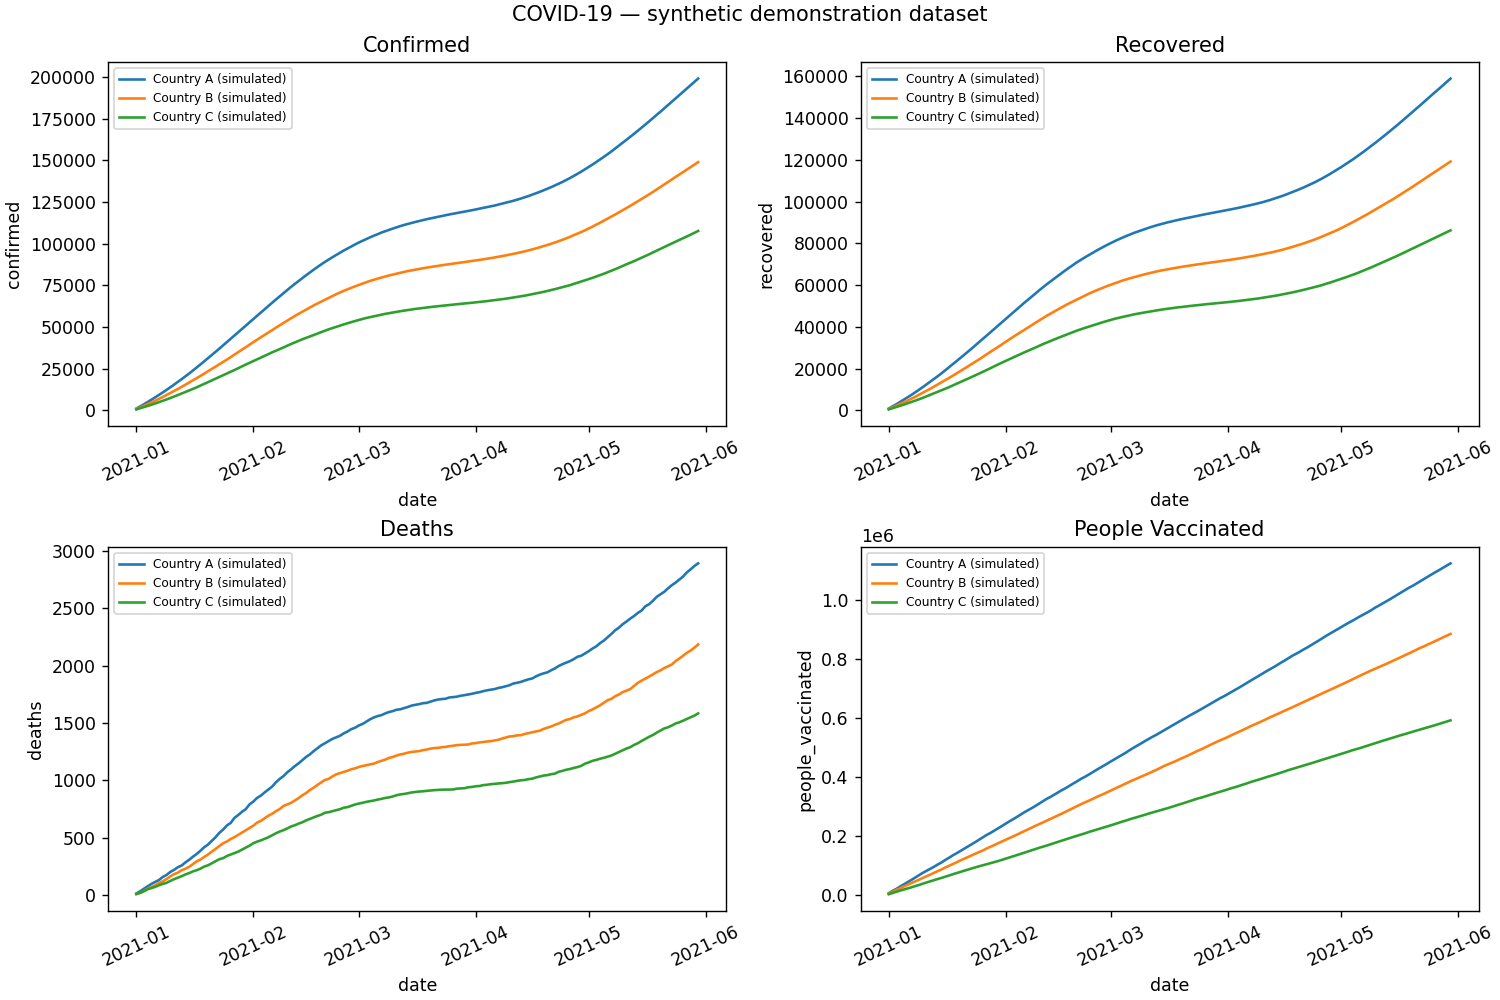

In [4]:
from IPython.display import display, Image
display(Image(filename="outputs/lab_09/covid_dashboard_preview.png"))

**Interpretation:** Each color denotes a simulated country. Rising cumulative lines indicate new cumulative events. The HTML dashboard supports hover, zoom and legend selection.

## Step 4 — Analyze synthetic sales, profitability and segments

In [5]:
from lab_09 import sales_dashboard
sales_findings = sales_dashboard()
print(sales_findings)

{'records': 2000, 'distinct_customers': 200, 'total_sales_inr': 63880103.63, 'total_profit_inr': 17883232.78, 'top_product_by_revenue': 'Laptop', 'top_region_by_profit': 'South', 'nulls_before_cleaning': {'order_id': 0, 'date': 0, 'customer_id': 0, 'region': 0, 'product': 0, 'quantity': 0, 'sales': 0, 'cost': 0}, 'note': 'All figures are simulated business records, not real transactions.'}


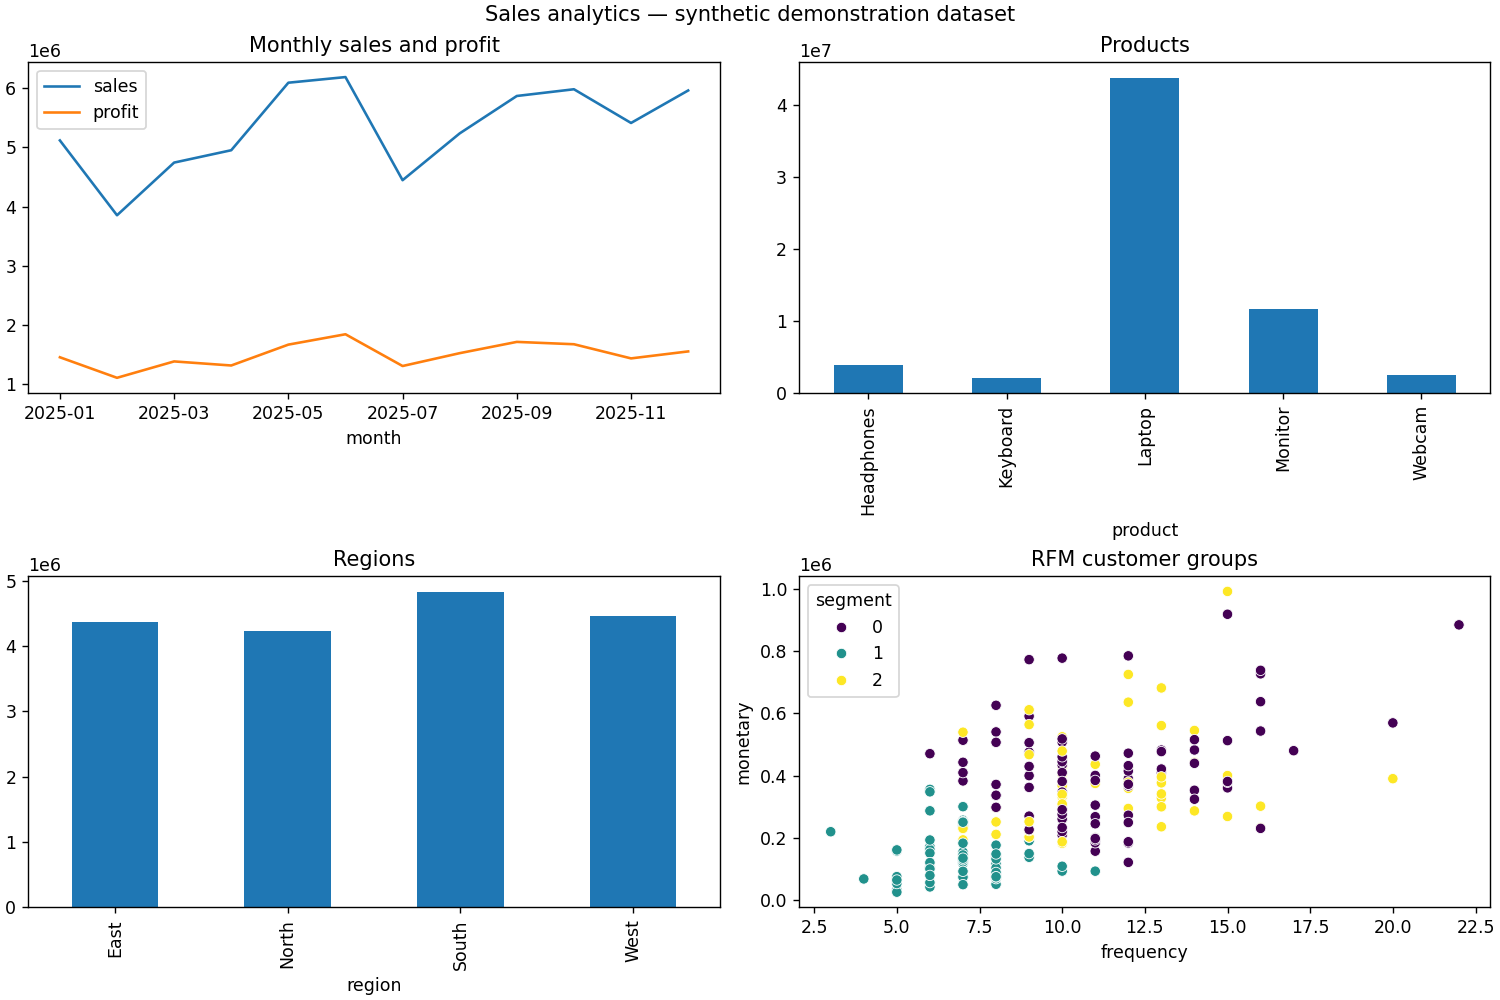

In [6]:
display(Image(filename="outputs/lab_09/sales_dashboard_preview.png"))

**Interpretation:** Revenue and profit are different metrics. Customer segments are built from frequency, monetary spend and recency, standardized before K-Means. Cluster numbers are arbitrary identifiers.

## Step 5 — Open interactive HTML dashboards

In [7]:
from IPython.display import FileLink
display(FileLink("outputs/lab_09/covid_dashboard.html"))
display(FileLink("outputs/lab_09/sales_dashboard.html"))

/mnt/data/ml_labs_09_10/outputs/lab_09/covid_dashboard.html

/mnt/data/ml_labs_09_10/outputs/lab_09/sales_dashboard.html

## Conclusion
Four core analytics objectives are met using reproducible demonstration data. To analyze real data, obtain a trustworthy source, document geography/date definitions, confirm measurement units, and validate missing data and cumulative reporting adjustments.